In [ ]:
import warnings
warnings.filterwarnings('ignore')
warnings.simplefilter('ignore')
from torchvision.models.segmentation import deeplabv3_resnet50
import torch
import torch.functional as F
import numpy as np
import requests
import torchvision
from PIL import Image
from pytorch_grad_cam.utils.image import show_cam_on_image, preprocess_image
from novas.datasets.avspeech_dataset import AVSpeechDataset
from trainer import parser
from novas.models.wavenet import update_args, WaveNet
import os
from novas.datasets.ss_speech_dataset import to_tensor

Global seed set to 1


In [2]:
model_name_dir = "novas_av_re_vis"
version = "v1"
pretrained_weights = os.path.join("data/models", model_name_dir, version, "best_val.ckpt")
state_dict = torch.load(pretrained_weights, map_location='cpu')
args = parser.parse_args("")
update_args(args, 
        vars(state_dict['hparams']))
#args.eval_clean = True
#args.use_librispeech = True
#args.use_frozen_dereverb = False
model = WaveNet(args)
model.load_state_dict(state_dict['state_dict'])
model.eval()

WaveNet(
  (visual_encoder): Sequential(
    (0): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
    (4): Sequential(
      (0): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (relu): ReLU(inplace=True)
        (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      )
      (1): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stat

In [3]:
dataset = AVSpeechDataset
data = dataset(split=args.test_split, use_rgb=True, use_depth=True, hop_length=args.hop_length,
                            remove_oov=args.remove_oov,
                            deterministic_eval=True, use_librispeech=args.use_librispeech,
                            convolve_random_rir=args.convolve_random_rir, use_da=args.use_da,
                            read_mp4=args.read_mp4, use_recv_audio=args.use_recv_audio,
                            use_dereverb_sspeech=args.use_dereverb_sspeech,
                            use_frozen_dereverb=args.use_frozen_dereverb)

NUM TOTAL FILES:
123841
Number of rirs: 297


In [4]:
input_tensor = data[0]
rgb_image = input_tensor['src_rgb']
for key in input_tensor:
    print(key)
    input_tensor[key] = to_tensor(input_tensor[key])
    input_tensor[key] = torch.unsqueeze(input_tensor[key], 0)

src_wav
tgt_wav
original_rgb
src_rgb
src_depth
rir


In [5]:
if torch.cuda.is_available():
    model = model.cuda()
    for key in input_tensor:
        input_tensor[key] = input_tensor[key].cuda()

output = model.audio_synthesis(input_tensor, 0, phase='test')
pred, tgt = output['pred'].detach(), output['tgt'].detach()

wav_dict = {
            'pred': pred if args.decode_wav else model.spec2wav(pred, input_tensor['src_wav']),
            'tgt': input_tensor['tgt_wav'],
            'input': input_tensor['src_wav']
}

In [6]:
class VAMTarget:
    def __init__(self, output):
        

    def __call__(self, model_output):
        return (np.abs(model_output['pred']-model_output['tgt'])).sum()

In [9]:
target_layers = [model.visual_encoder[-1]]
targets = [VAMTarget(wav_dict)]

In [10]:
input_tensor['src_wav'].shape

torch.Size([40960])

In [25]:
from pytorch_grad_cam import GradCAM
#print(input_tensor['src_rgb'].squeeze().shape)

with GradCAM(model=model,
             target_layers=target_layers,
             use_cuda=torch.cuda.is_available()) as cam:
    grayscale_cam = cam(input_tensor=input_tensor['src_rgb'].squeeze(),
                        targets=targets)
    #print(grayscale_cam.shape)
    cam_image = show_cam_on_image(rgb_image, grayscale_cam, use_rgb=True)

Image.fromarray(cam_image)

An exception occurred in CAM with block: <class 'IndexError'>. Message: too many indices for tensor of dimension 3


NameError: name 'cam_image' is not defined

In [ ]:
normalized_masks = torch.nn.functional.softmax(output, dim=1).cpu()
sem_classes = [
    '__background__', 'aeroplane', 'bicycle', 'bird', 'boat', 'bottle', 'bus',
    'car', 'cat', 'chair', 'cow', 'diningtable', 'dog', 'horse', 'motorbike',
    'person', 'pottedplant', 'sheep', 'sofa', 'train', 'tvmonitor'
]
sem_class_to_idx = {cls: idx for (idx, cls) in enumerate(sem_classes)}

car_category = sem_class_to_idx["car"]
car_mask = normalized_masks[0, :, :, :].argmax(axis=0).detach().cpu().numpy()
car_mask_uint8 = 255 * np.uint8(car_mask == car_category)
car_mask_float = np.float32(car_mask == car_category)

both_images = np.hstack((image, np.repeat(car_mask_uint8[:, :, None], 3, axis=-1)))
Image.fromarray(both_images)

In [25]:
model = deeplabv3_resnet50(pretrained=True, progress=False)
model = model.eval()

In [32]:
model.backbone.layer4

Sequential(
  (0): Bottleneck(
    (conv1): Conv2d(1024, 512, kernel_size=(1, 1), stride=(1, 1), bias=False)
    (bn1): BatchNorm2d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (conv2): Conv2d(512, 512, kernel_size=(3, 3), stride=(1, 1), padding=(2, 2), dilation=(2, 2), bias=False)
    (bn2): BatchNorm2d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (conv3): Conv2d(512, 2048, kernel_size=(1, 1), stride=(1, 1), bias=False)
    (bn3): BatchNorm2d(2048, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (relu): ReLU(inplace=True)
    (downsample): Sequential(
      (0): Conv2d(1024, 2048, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (1): BatchNorm2d(2048, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
  )
  (1): Bottleneck(
    (conv1): Conv2d(2048, 512, kernel_size=(1, 1), stride=(1, 1), bias=False)
    (bn1): BatchNorm2d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=Tr

In [12]:




class SemanticSegmentationTarget:
    def __init__(self, category, mask):
        self.category = category
        self.mask = torch.from_numpy(mask)
        if torch.cuda.is_available():
            self.mask = self.mask.cuda()
        
    def __call__(self, model_output):
        return (model_output[self.category, :, : ] * self.mask).sum()

    
target_layers = [model.model.backbone.layer4]
targets = [SemanticSegmentationTarget(car_category, car_mask_float)]
with GradCAM(model=model,
             target_layers=target_layers,
             use_cuda=torch.cuda.is_available()) as cam:
    grayscale_cam = cam(input_tensor=input_tensor,
                        targets=targets)[0, :]
    cam_image = show_cam_on_image(rgb_img, grayscale_cam, use_rgb=True)

Image.fromarray(cam_image)

AttributeError: 'WaveNet' object has no attribute 'model'

In [26]:
image_url = "https://farm1.staticflickr.com/6/9606553_ccc7518589_z.jpg"
image = np.array(Image.open(requests.get(image_url, stream=True).raw))
rgb_img = np.float32(image) / 255

In [27]:
input_tensor = preprocess_image(rgb_img,
                                mean=[0.485, 0.456, 0.406],
                                std=[0.229, 0.224, 0.225])
# Taken from the torchvision tutorial
# https://pytorch.org/vision/stable/auto_examples/plot_visualization_utils.html
model = deeplabv3_resnet50(pretrained=True, progress=False)
model = model.eval()

if torch.cuda.is_available():
    model = model.cuda()
    input_tensor = input_tensor.cuda()

output = model(input_tensor)

The history saving thread hit an unexpected error (OperationalError('disk I/O error')).History will not be written to the database.


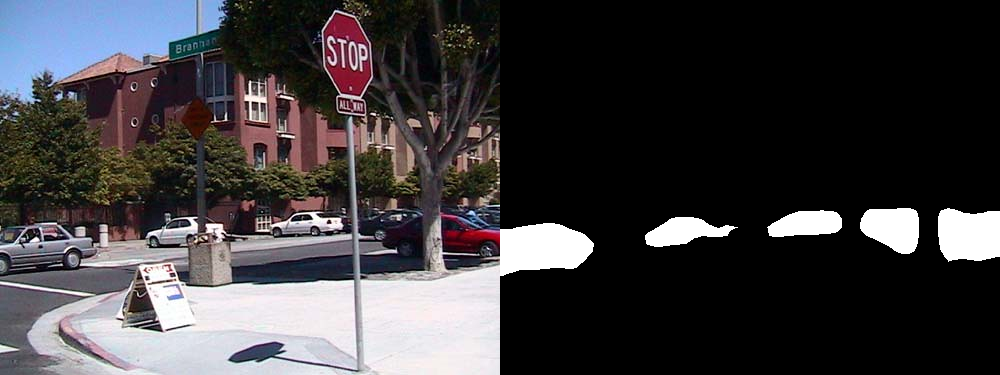

In [29]:
normalized_masks = torch.nn.functional.softmax(output, dim=1).cpu()
sem_classes = [
    '__background__', 'aeroplane', 'bicycle', 'bird', 'boat', 'bottle', 'bus',
    'car', 'cat', 'chair', 'cow', 'diningtable', 'dog', 'horse', 'motorbike',
    'person', 'pottedplant', 'sheep', 'sofa', 'train', 'tvmonitor'
]
sem_class_to_idx = {cls: idx for (idx, cls) in enumerate(sem_classes)}

car_category = sem_class_to_idx["car"]
car_mask = normalized_masks[0, :, :, :].argmax(axis=0).detach().cpu().numpy()
car_mask_uint8 = 255 * np.uint8(car_mask == car_category)
car_mask_float = np.float32(car_mask == car_category)

both_images = np.hstack((image, np.repeat(car_mask_uint8[:, :, None], 3, axis=-1)))
Image.fromarray(both_images)

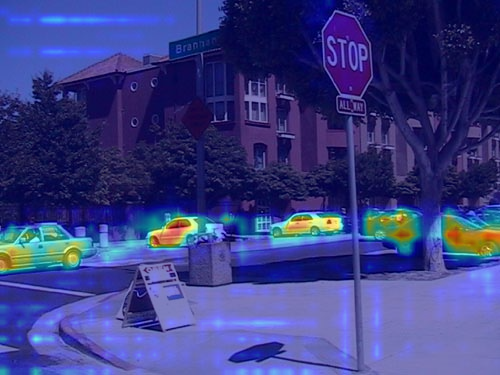

In [53]:
from pytorch_grad_cam import GradCAM

class SemanticSegmentationTarget:
    def __init__(self, category, mask):
        self.category = category
        self.mask = torch.from_numpy(mask)
        if torch.cuda.is_available():
            self.mask = self.mask.cuda()
        
    def __call__(self, model_output):
        return (model_output[self.category, :, : ] * self.mask).sum()

    
target_layers = [model.model.backbone.layer4]
targets = [SemanticSegmentationTarget(car_category, car_mask_float)]
with GradCAM(model=model,
             target_layers=target_layers,
             use_cuda=torch.cuda.is_available()) as cam:
    grayscale_cam = cam(input_tensor=input_tensor,
                        targets=targets)[0, :]
    cam_image = show_cam_on_image(rgb_img, grayscale_cam, use_rgb=True)

Image.fromarray(cam_image)
    

In [62]:
targets[0](2)

TypeError: 'int' object is not subscriptable

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


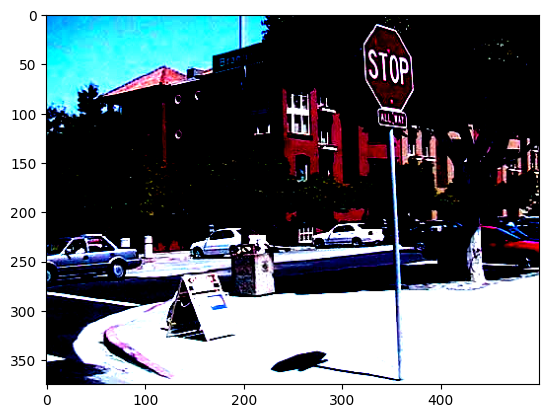

In [54]:
plt.imshow(input_tensor.cpu().squeeze().permute(1, 2, 0))

In [55]:
targets

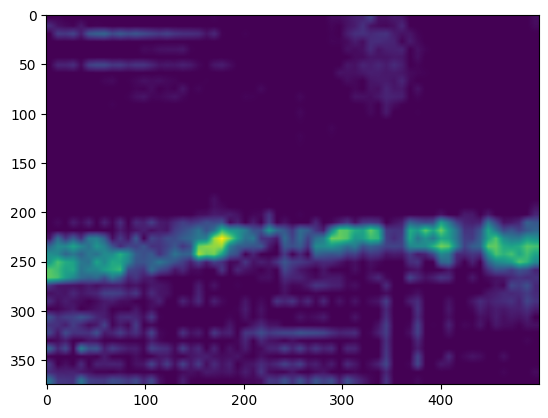

In [56]:
plt.imshow(grayscale_cam)